In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from sklearn.metrics import confusion_matrix
import joblib

In [ ]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)

y = iris.target

print(X.head())
print(X.shape)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
(150, 4)


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans.fit(X_scaled)

clusters = kmeans.labels_

print(clusters)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


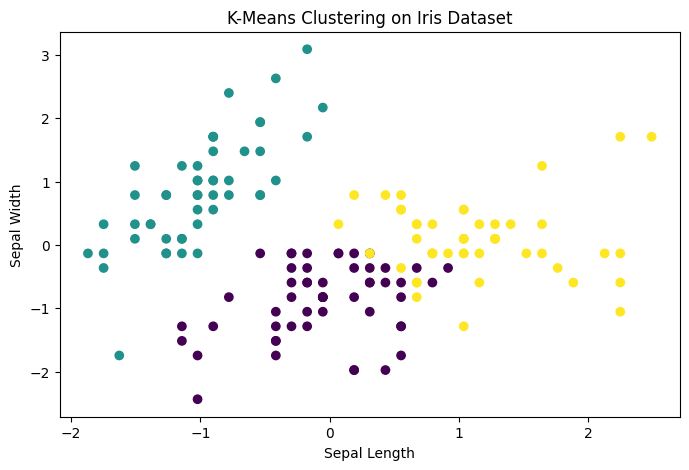

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=clusters,
    cmap='viridis'
)

plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.title('K-Means Clustering on Iris Dataset')

plt.show()

In [ ]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)

(150, 2)


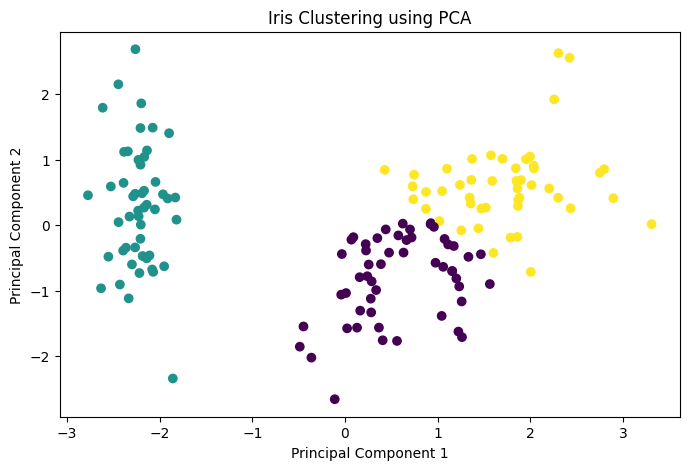

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters,
    cmap='viridis'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.title('Iris Clustering using PCA')

plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Actual Species': iris.target_names[y],
    'Predicted Cluster': clusters
})

print(comparison.head(15))

   Actual Species  Predicted Cluster
0          setosa                  1
1          setosa                  1
2          setosa                  1
3          setosa                  1
4          setosa                  1
5          setosa                  1
6          setosa                  1
7          setosa                  1
8          setosa                  1
9          setosa                  1
10         setosa                  1
11         setosa                  1
12         setosa                  1
13         setosa                  1
14         setosa                  1


In [ ]:
print(pd.crosstab(
    comparison['Actual Species'],
    comparison['Predicted Cluster']
))

Predicted Cluster   0   1   2
Actual Species               
setosa              0  50   0
versicolor         39   0  11
virginica          14   0  36


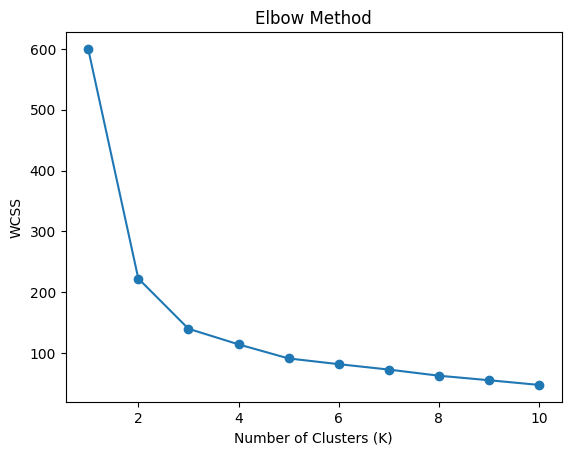

In [ ]:
wcss = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')

plt.title('Elbow Method')

plt.show()

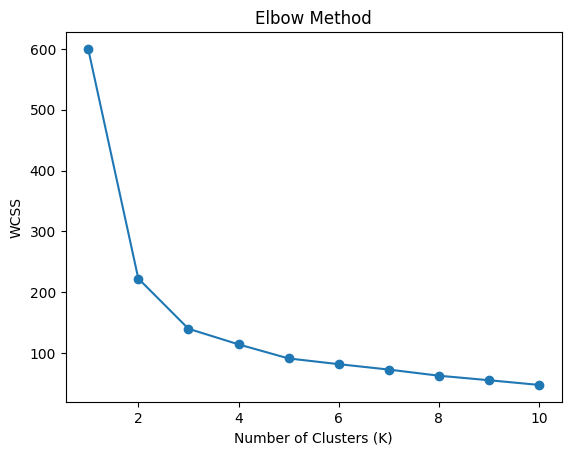

In [ ]:
wcss = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')

plt.title('Elbow Method')

plt.show()

In [ ]:
joblib.dump(kmeans, 'iris_kmeans.pkl')

['iris_kmeans.pkl']

In [ ]:
loaded_model = joblib.load('iris_kmeans.pkl')

print(loaded_model.predict(X_scaled[:5]))

[1 1 1 1 1]
